# 6. Затухание света в детекторе

Для фотона, прошедшего путь `L`, вероятность выживания равна `exp(-L / λ)`, где длина затухания `λ = 8 м = 800 см`. Моделируются источники с энергией 1 МэВ в разных точках вертикальной оси. Для каждой позиции сравниваются распределения полного заряда с затуханием и без него. Радиус детектора задан в сантиметрах.

In [1]:
from math import acos, cos, pi, sin
import numpy as np
import matplotlib.pyplot as plt

class Detector:
    def __init__(self):
        self.R = 200.0
        self.N = 40
        self.r = 10.0
        self.a = 0.5

    def get_pmt_positions(self):
        positions = []
        for i in range(self.N):
            phi = acos(1 - 2 * (i + 0.5) / self.N)
            theta = pi * (1 + np.sqrt(5)) * i
            positions.append((
                self.R * cos(theta) * sin(phi),
                self.R * sin(theta) * sin(phi),
                self.R * cos(phi)
            ))
        return positions

class Source:
    def __init__(self, Y=10000):
        self.Y = Y


def simulate_charge_pair(
    energy, source_position, detector, source, rng,
    attenuation_length_cm=800.0, number_of_events=1000, event_batch_size=8
):
    source_position = np.asarray(source_position, dtype=float)
    source_radius_squared = np.dot(source_position, source_position)
    if source_radius_squared >= detector.R**2:
        raise ValueError("Источник должен находиться внутри детектора")
    if attenuation_length_cm <= 0:
        raise ValueError("Длина затухания должна быть положительной")

    pmt_normals = np.asarray(detector.get_pmt_positions()) / detector.R
    projection_threshold = np.sqrt(detector.R**2 - detector.r**2)
    charges_without_attenuation = np.empty(number_of_events, dtype=np.int64)
    charges_with_attenuation = np.empty(number_of_events, dtype=np.int64)

    for batch_start in range(0, number_of_events, event_batch_size):
        batch_end = min(batch_start + event_batch_size, number_of_events)
        batch_events = batch_end - batch_start
        photon_counts = rng.poisson(lam=source.Y * energy, size=batch_events)
        event_indices = np.repeat(np.arange(batch_events), photon_counts)
        photon_count = len(event_indices)

        if photon_count == 0:
            charges_without_attenuation[batch_start:batch_end] = 0
            charges_with_attenuation[batch_start:batch_end] = 0
            continue

        cos_theta = rng.uniform(-1.0, 1.0, photon_count)
        phi = rng.uniform(0.0, 2 * np.pi, photon_count)
        sin_theta = np.sqrt(1.0 - cos_theta**2)
        directions = np.column_stack((
            sin_theta * np.cos(phi),
            sin_theta * np.sin(phi),
            cos_theta
        ))

        source_dot_direction = directions @ source_position
        distance_to_boundary = -source_dot_direction + np.sqrt(
            source_dot_direction**2 + detector.R**2 - source_radius_squared
        )
        boundary_points = source_position + distance_to_boundary[:, None] * directions
        projections = boundary_points @ pmt_normals.T
        hits_without_attenuation = np.any(
            projections >= projection_threshold, axis=1
        )

        survival_probability = np.exp(-distance_to_boundary / attenuation_length_cm)
        survives = rng.random(photon_count) < survival_probability
        hits_with_attenuation = hits_without_attenuation & survives

        hits_without_by_event = np.bincount(
            event_indices, weights=hits_without_attenuation, minlength=batch_events
        ).astype(np.int64)
        hits_with_by_event = np.bincount(
            event_indices, weights=hits_with_attenuation, minlength=batch_events
        ).astype(np.int64)

        charges_without_attenuation[batch_start:batch_end] = rng.poisson(
            lam=detector.a * hits_without_by_event
        )
        charges_with_attenuation[batch_start:batch_end] = rng.poisson(
            lam=detector.a * hits_with_by_event
        )

    return charges_without_attenuation, charges_with_attenuation

detector = Detector()
source = Source()
rng = np.random.default_rng(20261101)
energy = 1.0
attenuation_length_m = 8.0
attenuation_length_cm = attenuation_length_m * 100

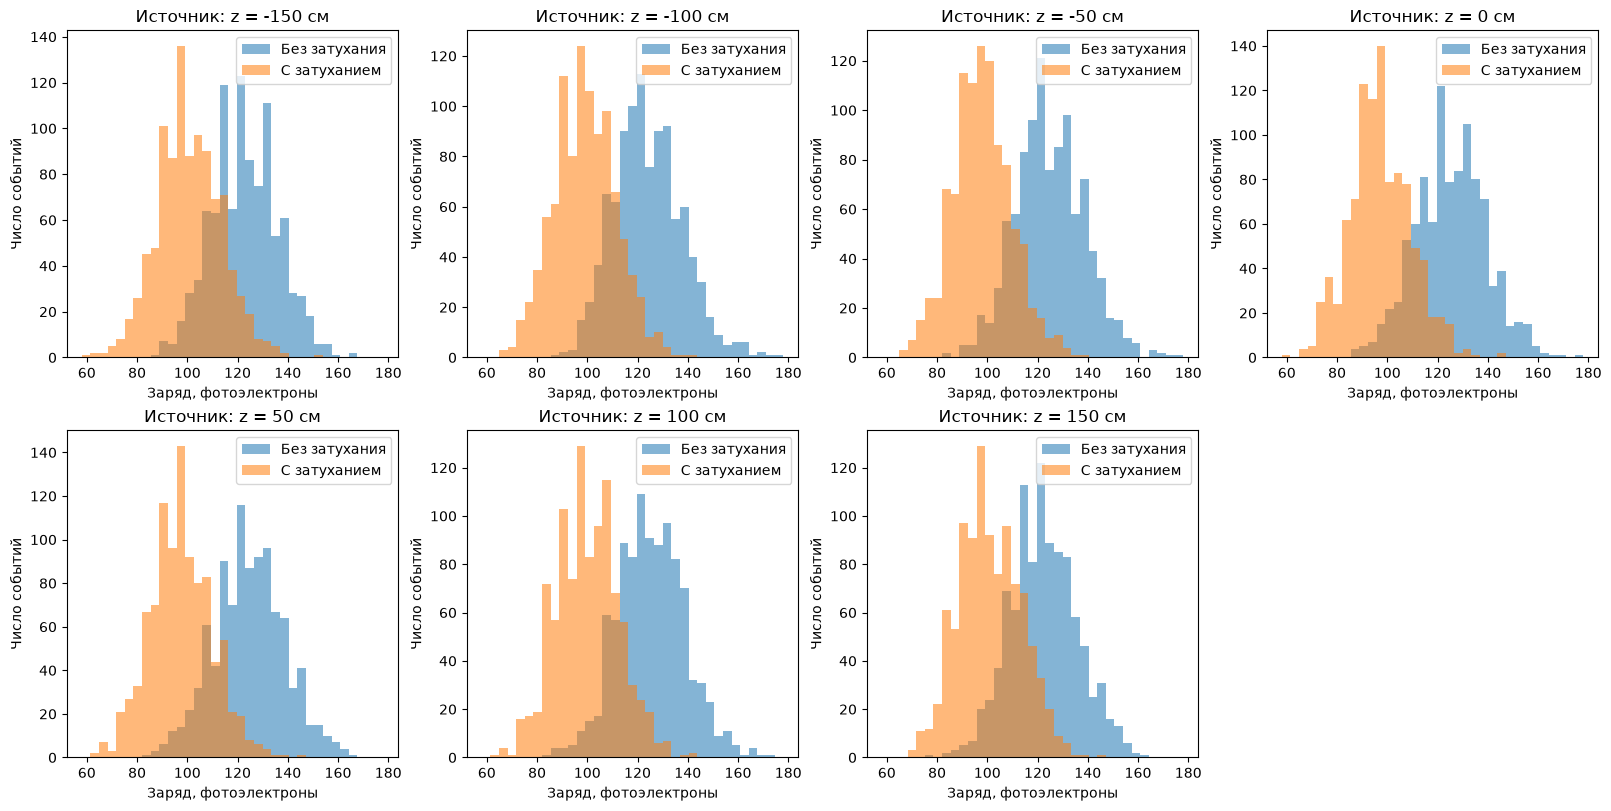

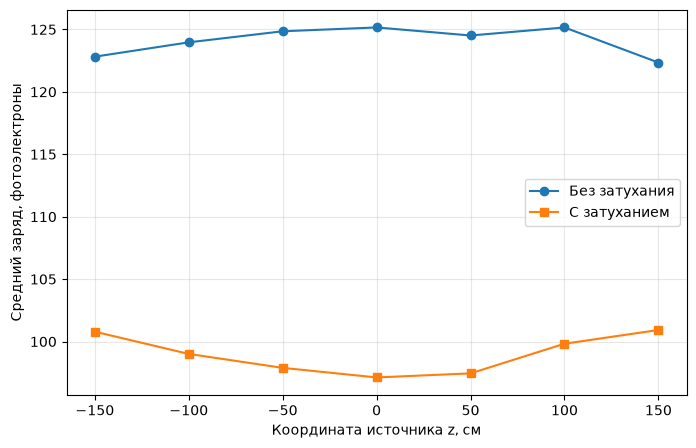

z (см) | Среднее без затухания | Среднее с затуханием | Снижение (%)
  -150 |                122.82 |               100.79 |       17.93
  -100 |                123.96 |                99.01 |       20.13
   -50 |                124.85 |                97.89 |       21.59
     0 |                125.16 |                97.12 |       22.40
    50 |                124.51 |                97.45 |       21.73
   100 |                125.16 |                99.83 |       20.24
   150 |                122.35 |               100.92 |       17.51


In [2]:
z_positions_cm = np.arange(-150, 151, 50)
results = {}
for z_position in z_positions_cm:
    no_attenuation, with_attenuation = simulate_charge_pair(
        energy=energy,
        source_position=(0.0, 0.0, float(z_position)),
        detector=detector,
        source=source,
        rng=rng,
        attenuation_length_cm=attenuation_length_cm,
        number_of_events=1000
    )
    results[int(z_position)] = {
        "without_attenuation": no_attenuation,
        "with_attenuation": with_attenuation
    }

all_charges = np.concatenate([
    values[key]
    for values in results.values()
    for key in ("without_attenuation", "with_attenuation")
])
histogram_bins = np.histogram_bin_edges(all_charges, bins=35)
fig, axes = plt.subplots(2, 4, figsize=(16, 8), constrained_layout=True)
for axis, z_position in zip(axes.flat, z_positions_cm):
    no_attenuation = results[int(z_position)]["without_attenuation"]
    with_attenuation = results[int(z_position)]["with_attenuation"]
    axis.hist(no_attenuation, bins=histogram_bins, alpha=0.55, label="Без затухания")
    axis.hist(with_attenuation, bins=histogram_bins, alpha=0.55, label="С затуханием")
    axis.set_title(f"Источник: z = {z_position} см")
    axis.set_xlabel("Заряд, фотоэлектроны")
    axis.set_ylabel("Число событий")
    axis.legend()
axes.flat[-1].axis("off")
plt.show()

mean_without = np.array([
    results[int(z)]["without_attenuation"].mean() for z in z_positions_cm
])
mean_with = np.array([
    results[int(z)]["with_attenuation"].mean() for z in z_positions_cm
])
fig, axis = plt.subplots(figsize=(8, 5))
axis.plot(z_positions_cm, mean_without, "o-", label="Без затухания")
axis.plot(z_positions_cm, mean_with, "s-", label="С затуханием")
axis.set_xlabel("Координата источника z, см")
axis.set_ylabel("Средний заряд, фотоэлектроны")
axis.grid(True, alpha=0.3)
axis.legend()
plt.show()

print("z (см) | Среднее без затухания | Среднее с затуханием | Снижение (%)")
for z_position, no_attenuation_mean, with_attenuation_mean in zip(
    z_positions_cm, mean_without, mean_with
):
    reduction = (1 - with_attenuation_mean / no_attenuation_mean) * 100
    print(
        f"{z_position:>6} | {no_attenuation_mean:>21.2f} | "
        f"{with_attenuation_mean:>20.2f} | {reduction:>11.2f}"
    )